In [4]:
import pandas as pd

datos = [
 {"Requisito":"RF-02","Historia":"US-01","Caso_Uso":"CU-01","Diseño":"DS-01","Codigo":"sistema.html: vistaAuth()","Prueba":"TC-02"},
 {"Requisito":"RF-03","Historia":"US-02","Caso_Uso":"CU-02","Diseño":"DS-02","Codigo":"sistema.html: cargarPerfil(), nav(); schema.sql","Prueba":"TC-03"},
 {"Requisito":"RF-04","Historia":"US-03","Caso_Uso":"CU-03","Diseño":"DS-03","Codigo":"sistema.html: vistaPanel(); index.html: envio","Prueba":"TC-04"},
 {"Requisito":"RF-07","Historia":"US-04","Caso_Uso":"CU-04","Diseño":"DS-04","Codigo":"sistema.html: vistaRevision(), bajar()","Prueba":"TC-05"},
 {"Requisito":"RF-13","Historia":"US-05","Caso_Uso":"CU-05","Diseño":"DS-05","Codigo":"sistema.html: vistaPublica(); index.html: render()","Prueba":"TC-06"},
 {"Requisito":"RNF-01","Historia":"US-06","Caso_Uso":"Transversal","Diseño":"DS-06","Codigo":"Mensajes de estado en index.html y sistema.html","Prueba":"TC-07"},
 {"Requisito":"RNF-04","Historia":"US-07","Caso_Uso":"Transversal","Diseño":"DS-07","Codigo":"schema.sql (15 politicas RLS); esc()","Prueba":"TC-08"},
 {"Requisito":"RNF-07","Historia":"US-08","Caso_Uso":"Transversal","Diseño":"DS-08","Codigo":"Despliegue estatico en Netlify","Prueba":"TC-09"},
]
df = pd.DataFrame(datos)
display(df)

def trazabilidad_incompleta(df):
    campos = {"Historia": "sin historia", "Caso_Uso": "sin caso de uso",
              "Codigo": "sin código", "Prueba": "sin prueba"}
    filas = []
    for col, etiqueta in campos.items():
        vacios = df[df[col].fillna("").astype(str).str.strip() == ""]
        for req in vacios["Requisito"]:
            filas.append({"Requisito": req, "Problema": etiqueta})
    return pd.DataFrame(filas, columns=["Requisito", "Problema"])

print("Matriz NMS")
r = trazabilidad_incompleta(df)
print("Trazabilidad completa en los 8 requisitos." if r.empty else r.to_string(index=False))

ejemplo = pd.DataFrame([
 {"Requisito":"RF-01","Historia":"US-01","Caso_Uso":"CU-01","Diseño":"DS-01","Codigo":"login.py","Prueba":"TC-01"},
 {"Requisito":"RF-02","Historia":"US-02","Caso_Uso":"CU-02","Diseño":"DS-02","Codigo":"registro.py","Prueba":""},
])
print("Ejemplo del profe")
print(trazabilidad_incompleta(ejemplo).to_string(index=False))

df.to_csv("trazabilidad.csv", index=False)

,Requisito,Historia,Caso_Uso,Diseño,Codigo,Prueba
0,RF-02,US-01,CU-01,DS-01,sistema.html: vistaAuth(),TC-02
1,RF-03,US-02,CU-02,DS-02,"sistema.html: cargarPerfil(), nav(); schema.sql",TC-03
2,RF-04,US-03,CU-03,DS-03,sistema.html: vistaPanel(); index.html: envio,TC-04
3,RF-07,US-04,CU-04,DS-04,"sistema.html: vistaRevision(), bajar()",TC-05
4,RF-13,US-05,CU-05,DS-05,sistema.html: vistaPublica(); index.html: rend...,TC-06
5,RNF-01,US-06,Transversal,DS-06,Mensajes de estado en index.html y sistema.html,TC-07
6,RNF-04,US-07,Transversal,DS-07,schema.sql (15 politicas RLS); esc(),TC-08
7,RNF-07,US-08,Transversal,DS-08,Despliegue estatico en Netlify,TC-09


Matriz NMS
Trazabilidad completa en los 8 requisitos.
Ejemplo del profe
Requisito   Problema
    RF-02 sin prueba


,id,requisito,version_anterior,version_nueva,prioridad,impacto,estado
0,CR-01,RF-02,-,1.0,Alta,Alto,Aprobado
1,CR-01,RF-03,-,1.0,Alta,Alto,Aprobado
2,CR-01,RF-04,1.0,1.1,Alta,Alto,Aprobado
3,CR-01,RF-07,-,1.0,Alta,Alto,Aprobado
4,CR-01,RF-13,1.0,1.1,Alta,Alto,Aprobado
5,CR-01,RNF-04,1.0,1.1,Alta,Alto,Aprobado
6,CR-SEG-01,RNF-04,1.1,1.2,Alta,Medio,Pendiente
7,CR-SEG-01,RNF-05,1.0,1.1,Alta,Medio,Pendiente
8,CR-SEG-01,RNF-14,-,1.0,Alta,Medio,Pendiente


Cantidad de cambios: 2
Aprobados: 1
Rechazados: 0
Pendientes: 1

Cambios por prioridad:
 prioridad
Alta    2

Requisitos más modificados:
 requisito
RNF-04    2
RF-02     1
RF-04     1
RF-03     1
RF-07     1
RF-13     1
RNF-05    1
RNF-14    1


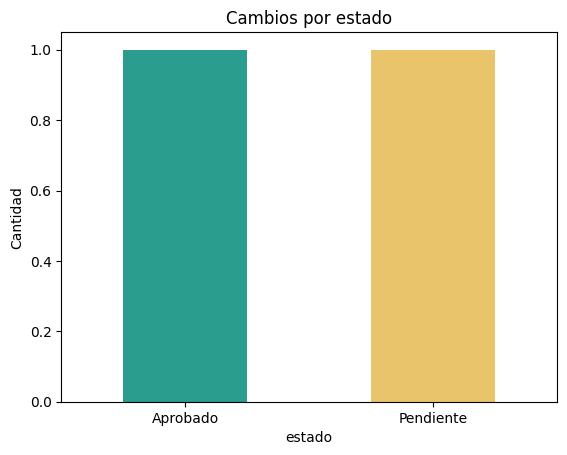

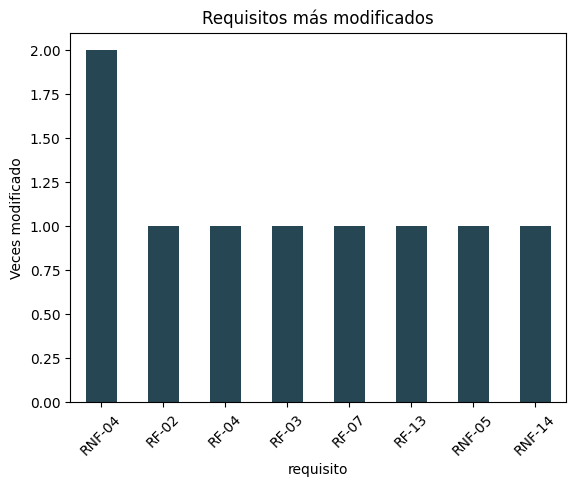

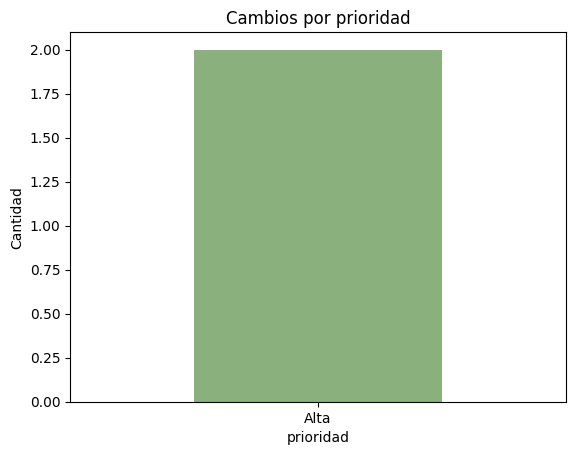

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

cambios = [
 {"id":"CR-01","requisito":"RF-02","version_anterior":"-","version_nueva":"1.0","prioridad":"Alta","impacto":"Alto","estado":"Aprobado"},
 {"id":"CR-01","requisito":"RF-03","version_anterior":"-","version_nueva":"1.0","prioridad":"Alta","impacto":"Alto","estado":"Aprobado"},
 {"id":"CR-01","requisito":"RF-04","version_anterior":"1.0","version_nueva":"1.1","prioridad":"Alta","impacto":"Alto","estado":"Aprobado"},
 {"id":"CR-01","requisito":"RF-07","version_anterior":"-","version_nueva":"1.0","prioridad":"Alta","impacto":"Alto","estado":"Aprobado"},
 {"id":"CR-01","requisito":"RF-13","version_anterior":"1.0","version_nueva":"1.1","prioridad":"Alta","impacto":"Alto","estado":"Aprobado"},
 {"id":"CR-01","requisito":"RNF-04","version_anterior":"1.0","version_nueva":"1.1","prioridad":"Alta","impacto":"Alto","estado":"Aprobado"},
 {"id":"CR-SEG-01","requisito":"RNF-04","version_anterior":"1.1","version_nueva":"1.2","prioridad":"Alta","impacto":"Medio","estado":"Pendiente"},
 {"id":"CR-SEG-01","requisito":"RNF-05","version_anterior":"1.0","version_nueva":"1.1","prioridad":"Alta","impacto":"Medio","estado":"Pendiente"},
 {"id":"CR-SEG-01","requisito":"RNF-14","version_anterior":"-","version_nueva":"1.0","prioridad":"Alta","impacto":"Medio","estado":"Pendiente"},
]
dc = pd.DataFrame(cambios)
display(dc)

unicos = dc.drop_duplicates("id")
print("Cantidad de cambios:", len(unicos))
print("Aprobados:", (unicos["estado"] == "Aprobado").sum())
print("Rechazados:", (unicos["estado"] == "Rechazado").sum())
print("Pendientes:", (unicos["estado"] == "Pendiente").sum())
print("\nCambios por prioridad:\n", unicos["prioridad"].value_counts().to_string())
mod = dc["requisito"].value_counts()
print("\nRequisitos más modificados:\n", mod.to_string())

unicos["estado"].value_counts().plot(kind="bar", color=["#2a9d8f", "#e9c46a", "#e76f51"][:unicos["estado"].nunique()])
plt.title("Cambios por estado"); plt.ylabel("Cantidad"); plt.xticks(rotation=0); plt.show()

mod.plot(kind="bar", color="#264653")
plt.title("Requisitos más modificados"); plt.ylabel("Veces modificado"); plt.xticks(rotation=45); plt.show()

unicos["prioridad"].value_counts().plot(kind="bar", color="#8ab17d")
plt.title("Cambios por prioridad"); plt.ylabel("Cantidad"); plt.xticks(rotation=0); plt.show()

dc.to_csv("cambios.csv", index=False)